# HidroClima Ecuador · Proyecto Integrador Parte 3
**Asignatura:** Prácticas y Herramientas de Big Data · **Integrantes:** Martin Andrade, Marlon Benavides, Zayo Vieira

**Pregunta del proyecto:** ¿lloverán mañana 6 mm o más en la cuenca del río Paute, cantidad a partir de la cual empieza a subir el caudal que llega al embalse Mazar?


Contenido:
1. Datos
2. Limpieza
3. Definición de características
4. Gráficos representativos con groupby
5. Definición de la variable objetivo
6. Comprobación con datos reales de Mazar
7. Modelos: regresión logística, SVM y Random Forest
8. Conclusión

In [ ]:
import pandas as pd

In [ ]:
import requests

In [ ]:
import time

## 1. Datos
Se usan dos fuentes abiertas de Open-Meteo, del 1 de enero de 2015 al 31 de diciembre de 2025:
- **API Historical Weather (reanálisis ERA5):** clima diario de 6 puntos de la cuenca del río Paute. Se eligieron puntos separados porque en ERA5 la lluvia tiene una resolución de unos 25 km y los puntos muy cercanos repiten la misma serie.
- **API Flood (modelo GloFAS):** caudal diario del río Paute en la zona del embalse Mazar.

En el primer avance se trabajaba con un solo punto por zona y dos zonas distintas. Ahora todos los datos son de la misma cuenca y cada día queda completo, sin filas descartadas.

In [ ]:
url_clima = "https://archive-api.open-meteo.com/v1/archive"

In [ ]:
variables = "temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,shortwave_radiation_sum,pressure_msl_mean,cloud_cover_mean"

In [ ]:
puntos = {"Cajas": (-2.80, -79.20), "Chiquintad": (-2.78, -79.00), "Cuenca": (-2.90, -79.00), "Azogues": (-2.74, -78.85), "Gualaceo": (-2.89, -78.78), "Mazar": (-2.59, -78.63)}

In [ ]:
def descargar(punto, lat, lon):
    # Descarga el clima diario de un punto de la cuenca desde Open-Meteo
    params = {"latitude": lat, "longitude": lon, "start_date": "2015-01-01", "end_date": "2025-12-31", "daily": variables, "timezone": "America/Guayaquil"}
    for intento in range(5):
        respuesta = requests.get(url_clima, params=params, timeout=60)
        if respuesta.status_code != 429:
            break
        time.sleep(60)  # 429 = demasiadas solicitudes, se espera un minuto
    respuesta.raise_for_status()
    datos = pd.DataFrame(respuesta.json()["daily"])
    datos.insert(0, "punto", punto)  # identifica de qué punto es cada fila
    return datos

La función define un tiempo máximo de espera y, si la API responde 429 por exceso de solicitudes, espera un minuto y vuelve a intentar.

In [ ]:
clima = pd.concat([descargar(p, lat, lon) for p, (lat, lon) in puntos.items()], ignore_index=True)

In [ ]:
params_caudal = {"latitude": -2.59, "longitude": -78.63, "start_date": "2015-01-01", "end_date": "2025-12-31", "daily": "river_discharge"}

In [ ]:
caudal = pd.DataFrame(requests.get("https://flood-api.open-meteo.com/v1/flood", params=params_caudal, timeout=60).json()["daily"])

In [ ]:
clima.shape

(24108, 12)

In [ ]:
caudal.shape

(4018, 2)

Se obtuvieron 24.108 registros de clima, 4.018 días por cada uno de los 6 puntos, y 4.018 días de caudal.

In [ ]:
clima.head()

,punto,time,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,shortwave_radiation_sum,pressure_msl_mean,cloud_cover_mean
0,Cajas,2015-01-01,13.1,6.8,11.2,11.2,13.0,89,5.5,13.68,1015.0,83
1,Cajas,2015-01-02,13.2,7.1,7.1,7.1,14.0,84,6.5,15.50,1014.5,83
2,Cajas,2015-01-03,13.2,7.2,5.2,5.2,9.0,82,6.2,16.68,1014.5,70
3,Cajas,2015-01-04,12.4,7.1,13.3,13.3,9.0,86,5.9,13.04,1015.7,75
4,Cajas,2015-01-05,12.1,6.3,1.9,1.9,9.0,83,5.0,15.38,1015.7,53


## 2. Limpieza

In [ ]:
clima.isna().sum().sum()

np.int64(0)

In [ ]:
caudal.isna().sum().sum()

np.int64(0)

In [ ]:
clima.duplicated(["punto", "time"]).sum()

np.int64(0)

No hay valores faltantes en ninguna de las dos fuentes ni registros duplicados por punto y fecha.

In [ ]:
(clima["precipitation_sum"] != clima["rain_sum"]).groupby(clima["punto"]).sum()

,0
punto,
Azogues,0
Cajas,697
Chiquintad,1
Cuenca,0
Gualaceo,0
Mazar,0


`rain_sum` solo cuenta la lluvia líquida. Difiere de `precipitation_sum` en 697 días en Cajas, el punto más alto, y en 1 día en Chiquintad. Se elimina `rain_sum` y se conserva la precipitación total, porque toda el agua que cae en la cuenca llega al río.

In [ ]:
clima = clima.drop(columns="rain_sum")

In [ ]:
clima = clima.rename(columns={"time": "fecha", "temperature_2m_max": "temp_max", "temperature_2m_min": "temp_min", "precipitation_sum": "precipitacion", "precipitation_hours": "horas_precipitacion", "relative_humidity_2m_mean": "humedad_media", "wind_speed_10m_max": "viento_max", "shortwave_radiation_sum": "radiacion", "pressure_msl_mean": "presion_media", "cloud_cover_mean": "nubosidad_media"})

In [ ]:
caudal = caudal.rename(columns={"time": "fecha", "river_discharge": "caudal"})

In [ ]:
clima["fecha"] = pd.to_datetime(clima["fecha"])

In [ ]:
caudal["fecha"] = pd.to_datetime(caudal["fecha"])

Se renombran las columnas al español y la fecha pasa de texto a tipo fecha para poder unir las dos fuentes.

Se agrupan los 6 puntos por fecha para tener un solo dato diario de toda la cuenca. La lluvia de la cuenca es el promedio de los puntos y además se guarda la lluvia máxima de un punto. Luego se une el caudal por fecha.

In [ ]:
# Un solo dato por día para toda la cuenca: promedio de los 6 puntos y lluvia máxima de un punto
cuenca = clima.groupby("fecha").agg(precipitacion=("precipitacion", "mean"), precip_max=("precipitacion", "max"), horas_precipitacion=("horas_precipitacion", "mean"), humedad_media=("humedad_media", "mean"), nubosidad_media=("nubosidad_media", "mean"), temp_max=("temp_max", "mean"), temp_min=("temp_min", "mean"), presion_media=("presion_media", "mean"), radiacion=("radiacion", "mean"), viento_max=("viento_max", "mean")).reset_index()

In [ ]:
cuenca = cuenca.merge(caudal, on="fecha")

In [ ]:
cuenca.shape

(4018, 12)

Validaciones: cada una debe devolver `True`.

In [ ]:
(cuenca["fecha"].diff().dt.days.dropna() == 1).all()

np.True_

In [ ]:
(cuenca["precipitacion"] >= 0).all()

np.True_

In [ ]:
cuenca["humedad_media"].between(0, 100).all()

np.True_

In [ ]:
(cuenca["caudal"] > 0).all()

np.True_

Todas las validaciones devuelven `True`: los días son consecutivos y no hay lluvia negativa, humedad fuera de rango ni caudal igual a cero. La tabla integrada tiene 4.018 días.

## 3. Definición de características

In [ ]:
cuenca["mes"] = cuenca["fecha"].dt.month

In [ ]:
cuenca["lluvia_7d"] = cuenca["precipitacion"].rolling(7).sum()

In [ ]:
cuenca["caudal_sube"] = cuenca["caudal"].shift(-1) > cuenca["caudal"].shift(1)  # True si el caudal de mañana supera al de ayer

| Característica | Qué representa | Por qué puede servir |
|---|---|---|
| `precipitacion` | Lluvia promedio de la cuenca hoy, en mm | Un día lluvioso suele seguir de otro lluvioso |
| `precip_max` | Lluvia del punto más lluvioso hoy | Detecta tormentas en una parte de la cuenca |
| `horas_precipitacion` | Horas con lluvia en el día | Lluvia continua indica un sistema que dura |
| `humedad_media` | Humedad relativa, en % | Aire húmedo favorece la lluvia |
| `nubosidad_media` | Porcentaje de cielo cubierto | Sin nubes no hay lluvia |
| `temp_max`, `temp_min` | Temperaturas en °C | Influyen en la evaporación y en la formación de nubes |
| `presion_media` | Presión al nivel del mar, en hPa | Cambios de presión anuncian cambios de tiempo |
| `radiacion` | Energía solar del día | Mucha radiación indica cielo despejado |
| `viento_max` | Viento máximo, en km/h | Movimiento de masas de aire |
| `caudal` | Caudal del río Paute, en m³/s | Resume la lluvia de los días anteriores |
| `lluvia_7d` | Lluvia acumulada de los últimos 7 días | Indica si la temporada está húmeda o seca |
| `mes` | Mes del año | La lluvia cambia por temporadas |

`caudal_sube` no es una característica del modelo. Es una columna auxiliar que vale `True` si el caudal de mañana es mayor que el de ayer y se usa para elegir el umbral de la variable objetivo.

In [ ]:
cuenca[["precipitacion", "precip_max", "horas_precipitacion", "humedad_media", "caudal", "lluvia_7d"]].describe()

,precipitacion,precip_max,horas_precipitacion,humedad_media,caudal,lluvia_7d
count,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4012.000000
mean,5.215489,11.333773,10.435665,81.948689,216.122797,36.527401
std,4.352366,8.343468,5.106739,5.367753,117.334201,17.999325
min,0.000000,0.000000,0.000000,49.000000,61.090000,0.116667
25%,2.037500,5.300000,6.833333,79.500000,129.620000,23.083333
50%,4.133333,9.400000,10.500000,82.333333,191.090000,33.950000
75%,7.200000,15.200000,13.833333,85.166667,270.020000,46.800000
max,35.400000,63.300000,24.000000,94.666667,865.960000,134.916667


La lluvia promedio de la cuenca es de 5,2 mm diarios, pero la mediana es de 4,1 mm: hay muchos días de poca lluvia y pocos de lluvia fuerte, hasta 35,4 mm. En un solo punto se llegó a 63,3 mm. El caudal va de 61 a 866 m³/s, con un promedio de 216 m³/s.

## 4. Gráficos representativos con groupby

### Gráfico 1. Lluvia promedio por punto de la cuenca

<Axes: ylabel='punto'>

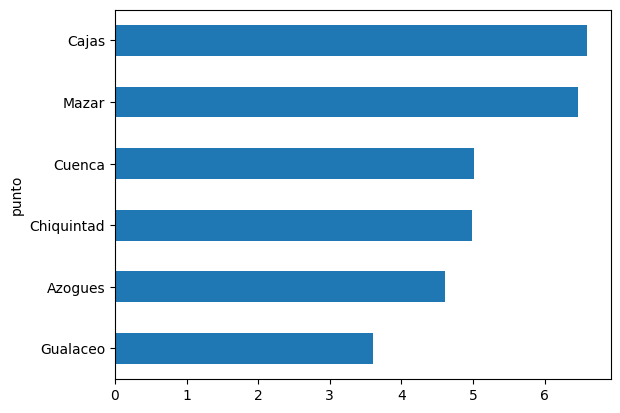

In [ ]:
clima.groupby("punto")["precipitacion"].mean().sort_values().plot(kind="barh")

Cajas y Mazar son los puntos más lluviosos, con 6,6 y 6,5 mm diarios, y Gualaceo el más seco, con 3,6 mm. La lluvia cambia bastante dentro de la cuenca, por eso no basta con un solo punto.

### Gráfico 2. Lluvia promedio de la cuenca por mes

<Axes: xlabel='mes'>

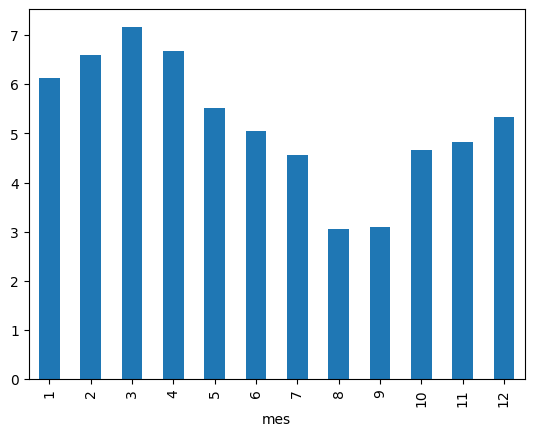

In [ ]:
cuenca.groupby("mes")["precipitacion"].mean().plot(kind="bar")

La cuenca tiene una temporada lluviosa de enero a abril, con el máximo en marzo, 7,2 mm diarios. Agosto y septiembre son los meses más secos, con unos 3 mm.

### Gráfico 3. Caudal promedio por mes

<Axes: xlabel='mes'>

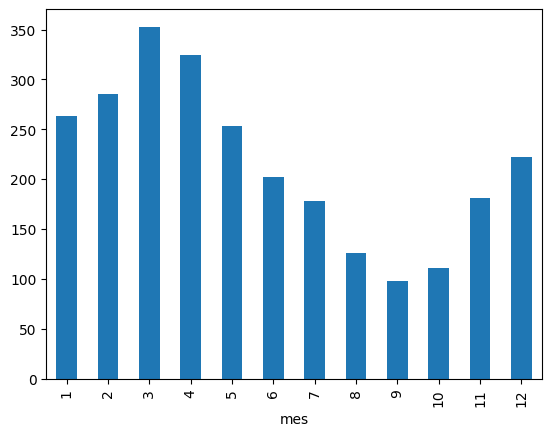

In [ ]:
cuenca.groupby("mes")["caudal"].mean().plot(kind="bar")

El caudal sigue el mismo patrón que la lluvia: el máximo es en marzo, con 353 m³/s, y el mínimo en septiembre, con 98 m³/s. El río responde a la temporada de lluvias.

### Gráfico 4. Caudal promedio por año

<Axes: xlabel='fecha'>

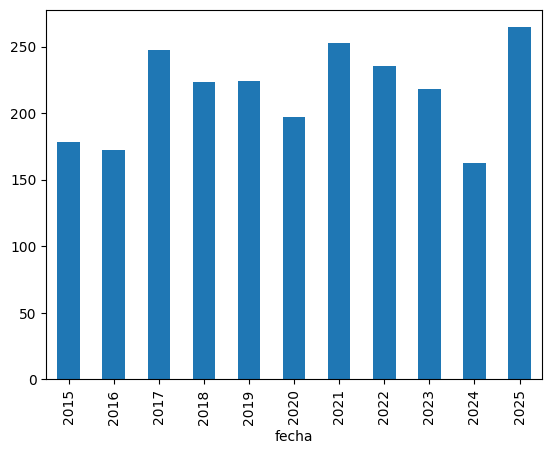

In [ ]:
cuenca.groupby(cuenca["fecha"].dt.year)["caudal"].mean().plot(kind="bar")

2024 tiene el caudal promedio más bajo del periodo, 162 m³/s, lo que coincide con la sequía que dejó sin agua a la central Mazar y provocó los cortes de luz en Ecuador. 2025 tiene el más alto, 265 m³/s.

### Gráfico 5. Proporción de días en que sube el caudal según la lluvia del día

<Axes: xlabel='precipitacion'>

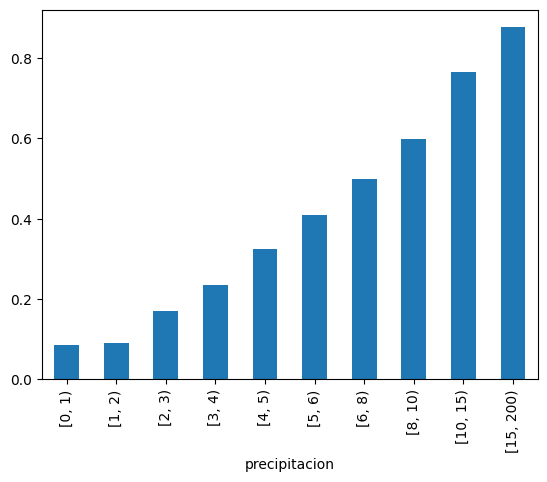

In [ ]:
cuenca.groupby(pd.cut(cuenca["precipitacion"], [0, 1, 2, 3, 4, 5, 6, 8, 10, 15, 200], right=False), observed=True)["caudal_sube"].mean().plot(kind="bar")

In [ ]:
cuenca.groupby(pd.cut(cuenca["precipitacion"], [0, 1, 2, 3, 4, 5, 6, 8, 10, 15, 200], right=False), observed=True)["caudal_sube"].agg(["mean", "count"])

,mean,count
precipitacion,,
"[0, 1)",0.084475,438
"[1, 2)",0.089888,534
"[2, 3)",0.169697,495
"[3, 4)",0.234568,486
"[4, 5)",0.324766,428
"[5, 6)",0.409524,315
"[6, 8)",0.497976,494
"[8, 10)",0.597561,328
"[10, 15)",0.765193,362


Con menos de 1 mm el caudal sube solo en el 8 % de los días. La proporción crece con la lluvia: 41 % entre 5 y 6 mm, 50 % entre 6 y 8 mm, 60 % entre 8 y 10 mm y 88 % con 15 mm o más. Desde 6 mm el caudal sube al menos en la mitad de los casos, por eso se toma como el umbral de lluvia importante para Mazar.

## 5. Definición de la variable objetivo

In [ ]:
cuenca["precip_manana"] = cuenca["precipitacion"].shift(-1)  # lluvia del día siguiente, se sube una fila

In [ ]:
cuenca["lluvia_manana"] = (cuenca["precip_manana"] >= 6).astype(int)

In [ ]:
cuenca = cuenca.drop(columns="caudal_sube").dropna()

In [ ]:
cuenca.shape

(4011, 16)

**Variable objetivo:** `lluvia_manana`, que vale 1 si mañana caen 6 mm o más en promedio en la cuenca y 0 si no. `precip_manana` guarda los milímetros de mañana para el problema de regresión. Se eliminan las 7 filas incompletas que generan el desplazamiento y la lluvia de 7 días, y quedan 4.011 días.

In [ ]:
cuenca["lluvia_manana"].value_counts()

,count
lluvia_manana,
0,2689
1,1322


Hay 1.322 días positivos y 2.689 negativos. El 33 % de los días tiene lluvia importante al día siguiente, así que las clases no están balanceadas.

### Gráfico 6. Proporción de días con lluvia importante al día siguiente por mes

<Axes: xlabel='mes'>

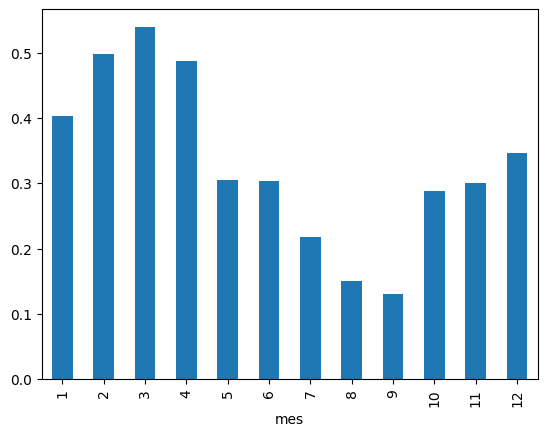

In [ ]:
cuenca.groupby("mes")["lluvia_manana"].mean().plot(kind="bar")

La lluvia importante es mucho más frecuente de febrero a abril, en cerca de la mitad de los días, y muy rara en agosto y septiembre, en menos del 15 %. Por eso el mes es una característica útil.

### Gráfico 7. Humedad y nubosidad de hoy según si mañana hay lluvia importante

<Axes: xlabel='lluvia_manana'>

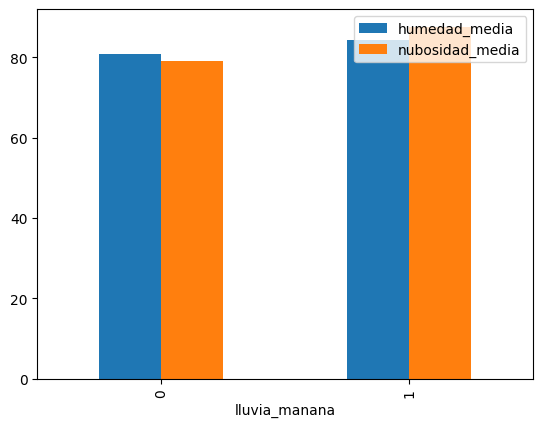

In [ ]:
cuenca.groupby("lluvia_manana")[["humedad_media", "nubosidad_media"]].mean().plot(kind="bar")

Los días antes de una lluvia importante tienen más humedad, 84 % frente a 81 %, y más nubosidad, 88 % frente a 79 %. La diferencia no es muy grande, lo que muestra que predecir la lluvia de mañana no será sencillo.

In [ ]:
cuenca.corr(numeric_only=True)["lluvia_manana"].sort_values()

,lluvia_manana
viento_max,-0.231300
mes,-0.165249
radiacion,-0.164035
presion_media,-0.127628
temp_max,-0.009386
caudal,0.244469
temp_min,0.271960
nubosidad_media,0.272035
lluvia_7d,0.287155
humedad_media,0.308246


Las características más relacionadas con el objetivo son la lluvia de hoy, 0,39, la lluvia máxima de un punto, las horas de lluvia y la humedad. El viento, la radiación y la presión tienen relación negativa. `precip_manana` aparece con 0,79 porque de ella sale el objetivo, por eso no se usa como entrada.

In [ ]:
cuenca.to_csv("hidroclima_mazar_preparado.csv", index=False)

In [ ]:
cuenca.to_parquet("hidroclima_mazar_preparado.parquet", index=False)

## 6. Comprobación con datos reales de Mazar
La profesora recomendó buscar un dataset pequeño con datos reales de Mazar, alinearlo por fechas con los datos de Open-Meteo y ver si de verdad hay relación antes de entrenar los modelos.

Se usa el **caudal diario que entra al embalse Mazar durante 2025**, publicado por CELEC Sur en su página de hidrología (generacioncsr.celec.gob.ec/graficasproduccion). Son datos medidos por la central, no estimados por un modelo como GloFAS. La página entrega un mes por consulta, por eso se descargan los 12 meses de 2025 con una pausa entre cada consulta.

In [ ]:
url_celec = "https://generacioncsr.celec.gob.ec:8443/ords/csr/sardomcsr/pointValuesMesAvg"

In [ ]:
def caudal_mes(mes):
    # Descarga el caudal diario de un mes de 2025 desde CELEC Sur
    inicio = pd.Timestamp(2025, mes, 1)
    fin = inicio + pd.offsets.MonthBegin()
    # 30538 es el código del caudal que entra a Mazar en la página de CELEC
    params = {"mrid": 30538, "fechaInicio": inicio.strftime("%Y-%m-%dT06:00:00.000Z"), "fechaFin": fin.strftime("%Y-%m-%dT05:00:00.000Z"), "fecha": inicio.strftime("%d/%m/%Y 01:00:00")}
    respuesta = requests.get(url_celec, params=params, timeout=60)
    respuesta.raise_for_status()  # detiene el notebook si la página responde con error
    datos = pd.DataFrame(respuesta.json()["items"])
    time.sleep(2)  # pausa para no saturar la página con consultas seguidas
    return pd.DataFrame({"fecha": pd.to_datetime(datos["loctimestamp"].str[:10]), "caudal_real": datos["valueedit"]})

`mrid` 30538 es el identificador del caudal de Mazar en la página de CELEC. La función pide un mes, verifica la respuesta y devuelve la fecha y el caudal en m³/s.

In [ ]:
celec = pd.concat([caudal_mes(m) for m in range(1, 13)]).sort_values("fecha", ignore_index=True)

In [ ]:
celec.shape

(365, 2)

In [ ]:
celec.head()

,fecha,caudal_real
0,2025-01-01,112.017585
1,2025-01-02,138.296889
2,2025-01-03,150.087896
3,2025-01-04,146.280175
4,2025-01-05,160.877349


In [ ]:
mini = cuenca.merge(celec, on="fecha")  # une la lluvia de Open-Meteo con el caudal real por fecha

In [ ]:
mini.shape

(364, 17)

Se obtuvieron 365 días de caudal real de 2025. Al unirlos por fecha con la tabla de la cuenca quedan 364 días, porque el 31 de diciembre se eliminó en la sección 5 al no tener dato del día siguiente. Este es el minidataset de comprobación: cada fila tiene la lluvia de Open-Meteo y el caudal real medido por CELEC.

In [ ]:
mini[["precipitacion", "caudal", "caudal_real"]].corr()

,precipitacion,caudal,caudal_real
precipitacion,1.000000,0.367044,0.500361
caudal,0.367044,1.000000,0.450742
caudal_real,0.500361,0.450742,1.000000


In [ ]:
mini["caudal_real"].corr(mini["precipitacion"].shift(1))  # lluvia de ayer contra caudal de hoy

np.float64(0.6085293469779559)

In [ ]:
mini["caudal_real"].corr(mini["precipitacion"].rolling(3).sum())  # lluvia acumulada de 3 días contra caudal de hoy

np.float64(0.6368213097812031)

La lluvia de la cuenca y el caudal real tienen una correlación de 0,50 en el mismo día. Si se compara la lluvia de ayer con el caudal de hoy sube a 0,61, y con la lluvia acumulada de 3 días llega a 0,64. Esto muestra que el agua tarda alrededor de un día en llegar al embalse. También se ve que la lluvia de Open-Meteo se relaciona mejor con el caudal real, 0,50, que con el caudal estimado por GloFAS, 0,37.

### Gráfico 8. Lluvia de la cuenca y caudal real de Mazar en febrero de 2025

<Axes: xlabel='fecha'>

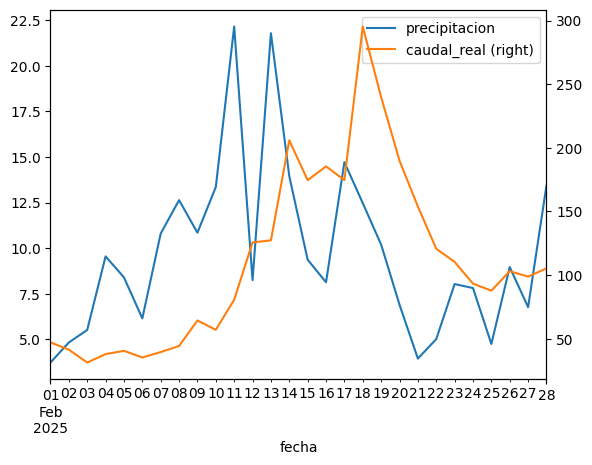

In [ ]:
mini[mini["fecha"].dt.month == 2].plot(x="fecha", y=["precipitacion", "caudal_real"], secondary_y="caudal_real")

Febrero de 2025 responde a la pregunta de la profesora: después de cada lluvia fuerte sube el caudal que llega a Mazar. El 11 de febrero llovieron 22 mm en la cuenca y el caudal pasó de 57 a 126 m³/s en dos días. El 13 cayeron otros 22 mm y subió a 206 m³/s, y después de la lluvia del 17 llegó a 295 m³/s, el valor más alto del mes.

### Gráfico 9. Proporción de días en que sube el caudal real según la lluvia del día

In [ ]:
mini["caudal_real_sube"] = mini["caudal_real"].shift(-1) > mini["caudal_real"].shift(1)

<Axes: xlabel='precipitacion'>

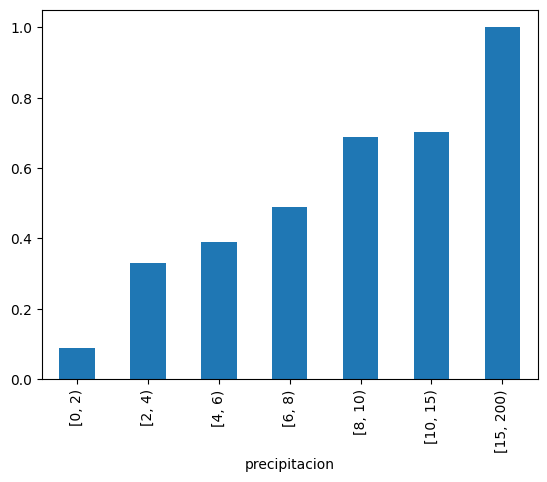

In [ ]:
mini.groupby(pd.cut(mini["precipitacion"], [0, 2, 4, 6, 8, 10, 15, 200], right=False), observed=True)["caudal_real_sube"].mean().plot(kind="bar")

In [ ]:
mini.groupby(pd.cut(mini["precipitacion"], [0, 2, 4, 6, 8, 10, 15, 200], right=False), observed=True)["caudal_real_sube"].agg(["mean", "count"])

,mean,count
precipitacion,,
"[0, 2)",0.088235,68
"[2, 4)",0.328947,76
"[4, 6)",0.390625,64
"[6, 8)",0.490566,53
"[8, 10)",0.687500,32
"[10, 15)",0.701754,57
"[15, 200)",1.000000,14


Con el caudal real se repite lo que se vio en el gráfico 5 con GloFAS. Con menos de 2 mm el caudal sube solo en el 9 % de los días; entre 6 y 8 mm sube en el 49 %, entre 8 y 10 mm en el 69 % y con 15 mm o más en todos los casos. El umbral de 6 mm de la variable objetivo queda respaldado con datos medidos en Mazar.

In [ ]:
mini[["caudal", "caudal_real"]].mean()

,0
caudal,264.697170
caudal_real,124.230007


En 2025 GloFAS estima un caudal promedio de 265 m³/s, pero el real fue de 124 m³/s. GloFAS sobreestima la cantidad de agua, aunque sube y baja con la lluvia. Por eso se mantiene como característica del modelo, ya que lo que aporta es la tendencia y no el valor exacto.

In [ ]:
celec.to_csv("caudal_mazar_celec_2025.csv", index=False)

**Conclusión de la comprobación:** sí hay relación entre la lluvia de Open-Meteo y el agua que llega a Mazar. La lluvia de un día se refleja en el caudal del día siguiente y, desde 6 mm, el caudal real sube al menos en la mitad de los casos. Con esto tiene sentido seguir con el modelo que predice la lluvia de mañana. El caudal descargado se guarda en `caudal_mazar_celec_2025.csv`.

## 7. Modelos: regresión logística, SVM y Random Forest
La guía del Proyecto Integrador pide implementar al menos tres modelos, compararlos con métricas apropiadas y elegir el mejor con una justificación técnica. Se eligieron tres modelos de clasificación supervisada:

| Modelo | Por qué se usa |
|---|---|
| Regresión logística | Modelo base, sencillo de interpretar y entrega probabilidades |
| SVM | Busca la frontera que mejor separa los días con y sin lluvia importante; con kernel RBF capta relaciones no lineales |
| Random Forest | Combina muchos árboles, capta relaciones no lineales y muestra qué variables pesan más |

Antes de elegir estos tres se probaron también KNN, Naive Bayes, Gradient Boosting y árbol de decisión con el mismo procedimiento. Quedaron por debajo o apenas por encima de la referencia, por eso no se incluyen.

**Procedimiento:**
- Se respeta el orden en el tiempo: se entrena con 2015 a 2020, se eligen los hiperparámetros y el umbral de decisión con 2021 y 2022, y se prueba con 2023 a 2025. El modelo final se vuelve a entrenar con 2015 a 2022.
- La métrica principal es el F1 de la clase positiva, porque solo el 33 % de los días tiene lluvia importante. El AUC se usa como métrica complementaria.
- Todos se comparan con la persistencia: suponer que mañana pasará lo mismo que hoy.

In [ ]:
import numpy as np

In [ ]:
from sklearn.pipeline import make_pipeline

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
from sklearn.svm import SVC

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score, ConfusionMatrixDisplay

In [ ]:
cuenca["mes_sin"] = np.sin(2 * np.pi * cuenca["mes"] / 12)  # el mes como ángulo para que diciembre y enero queden cerca

In [ ]:
cuenca["mes_cos"] = np.cos(2 * np.pi * cuenca["mes"] / 12)

El mes se transforma en seno y coseno para que diciembre y enero queden cerca, como pasa en la realidad. Los modelos de regresión logística y SVM usan estas dos columnas en lugar del número del mes. El Random Forest usa el mes directamente, porque los árboles no dependen de la escala.

In [ ]:
predictores = ["precipitacion", "precip_max", "horas_precipitacion", "humedad_media", "nubosidad_media", "temp_max", "temp_min", "presion_media", "radiacion", "viento_max", "caudal", "lluvia_7d", "mes"]

In [ ]:
lineales = [c for c in predictores if c != "mes"] + ["mes_sin", "mes_cos"]

In [ ]:
dia_predicho = cuenca["fecha"] + pd.Timedelta(days=1)  # el modelo predice el día siguiente, por eso se divide con esta fecha

In [ ]:
entrena = dia_predicho < "2021-01-01"

In [ ]:
valida = ~entrena & (dia_predicho < "2023-01-01")

In [ ]:
prueba = dia_predicho >= "2023-01-01"

In [ ]:
pd.Series({"Entrenamiento 2015-2020": entrena.sum(), "Validación 2021-2022": valida.sum(), "Prueba 2023-2025": prueba.sum()})

,0
Entrenamiento 2015-2020,2185
Validación 2021-2022,730
Prueba 2023-2025,1096


In [ ]:
y = cuenca["lluvia_manana"]

In [ ]:
def puntaje(modelo, X):
    # Devuelve un puntaje por día: mientras más alto, más probable la lluvia importante
    if hasattr(modelo, "decision_function"):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]

In [ ]:
def elegir_umbral(y_real, puntajes):
    # Prueba varios cortes del puntaje y se queda con el que da el mejor F1
    candidatos = np.unique(np.quantile(puntajes, np.arange(0.05, 0.951, 0.01)))
    f1s = [f1_score(y_real, (puntajes >= u).astype(int)) for u in candidatos]
    return max(u for u, f in zip(candidatos, f1s) if f == max(f1s))

In [ ]:
def evaluar(construir, rejilla, columnas):
    filas = []
    # 1. Entrena con 2015-2020 y mide en validación cada combinación de hiperparámetros
    for params in rejilla:
        modelo = construir(**params).fit(cuenca.loc[entrena, columnas], y[entrena])
        p_val = puntaje(modelo, cuenca.loc[valida, columnas])
        umbral = elegir_umbral(y[valida], p_val)
        filas.append({"params": params, "umbral": umbral, "f1_validacion": f1_score(y[valida], (p_val >= umbral).astype(int))})
    mejor = max(filas, key=lambda f: f["f1_validacion"])
    # 2. Vuelve a entrenar la mejor combinación con 2015-2022
    modelo = construir(**mejor["params"]).fit(cuenca.loc[entrena | valida, columnas], y[entrena | valida])
    # 3. Predice 2023-2025, datos que no se usaron para ninguna decisión
    p_te = puntaje(modelo, cuenca.loc[prueba, columnas])
    return {**mejor, "modelo": modelo, "puntaje": p_te, "pred": (p_te >= mejor["umbral"]).astype(int)}

`evaluar` entrena el modelo con cada combinación de hiperparámetros, elige en validación el umbral que da el mejor F1, se queda con la mejor combinación, la vuelve a entrenar con 2015 a 2022 y devuelve sus predicciones para 2023 a 2025. Así los datos de prueba no se usan para tomar ninguna decisión.

### 7.1 Regresión logística

In [ ]:
res_log = evaluar(lambda **p: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, **p)), [{"C": c} for c in [0.01, 0.1, 1, 10]], lineales)

In [ ]:
res_log["params"], res_log["f1_validacion"]

({'C': 0.01}, 0.6330708661417322)

### 7.2 SVM

In [ ]:
rejilla_svm = [{"kernel": "linear", "C": c} for c in [0.1, 1]] + [{"kernel": "rbf", "C": c, "gamma": g} for c in [0.1, 1, 10] for g in ["scale", 0.01, 0.1]]

In [ ]:
res_svm = evaluar(lambda **p: make_pipeline(StandardScaler(), SVC(class_weight="balanced", **p)), rejilla_svm, lineales)

In [ ]:
res_svm["params"], res_svm["f1_validacion"]

({'kernel': 'rbf', 'C': 10, 'gamma': 0.01}, 0.6486486486486487)

### 7.3 Random Forest

In [ ]:
rejilla_rf = [{"max_depth": d, "min_samples_leaf": h, "max_features": f} for d in [4, 6, 8, None] for h in [5, 20, 50] for f in ["sqrt", 0.5]]

In [ ]:
# random_state=314 fija la semilla para que el resultado se repita en cada ejecución
res_rf = evaluar(lambda **p: RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=314, **p), rejilla_rf, predictores)

In [ ]:
res_rf["params"], res_rf["f1_validacion"]

({'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 0.5},
 0.643312101910828)

Los mejores hiperparámetros elegidos en validación son: regresión logística con C = 0,01; SVM con kernel RBF, C = 10 y gamma = 0,01; y Random Forest con profundidad máxima de 8, al menos 5 días por hoja y la mitad de las variables en cada división.

### 7.4 Comparación en el periodo de prueba 2023 a 2025

In [ ]:
y_te = y[prueba]

In [ ]:
pred_persistencia = (cuenca.loc[prueba, "precipitacion"] >= 6).astype(int)  # referencia: mañana igual que hoy

In [ ]:
def metricas(pred, puntajes):
    return {"F1": f1_score(y_te, pred), "Recall": recall_score(y_te, pred), "Precision": precision_score(y_te, pred), "AUC": roc_auc_score(y_te, puntajes)}

In [ ]:
tabla = pd.DataFrame({"Regresión logística": metricas(res_log["pred"], res_log["puntaje"]), "SVM": metricas(res_svm["pred"], res_svm["puntaje"]), "Random Forest": metricas(res_rf["pred"], res_rf["puntaje"]), "Persistencia": metricas(pred_persistencia, cuenca.loc[prueba, "precipitacion"])}).T.round(3)

In [ ]:
tabla

,F1,Recall,Precision,AUC
Regresión logística,0.628,0.826,0.507,0.780
SVM,0.657,0.794,0.560,0.786
Random Forest,0.643,0.810,0.533,0.785
Persistencia,0.611,0.612,0.610,0.769


En el periodo de prueba, de 2023 a 2025:

- La **SVM** tiene el mejor F1, 0,657, y el mejor AUC, 0,786.
- El **Random Forest** queda cerca, con F1 de 0,643 y AUC de 0,785.
- La **regresión logística** detecta más días de lluvia, con recall de 0,826, pero da más falsas alarmas y su F1 baja a 0,628.
- Los tres superan a la **persistencia**, que tiene F1 de 0,611. La persistencia solo detecta el 61 % de los días con lluvia importante, mientras que los modelos detectan entre el 79 % y el 83 %.

### Gráfico 10. F1 y AUC de cada modelo en prueba

<Axes: >

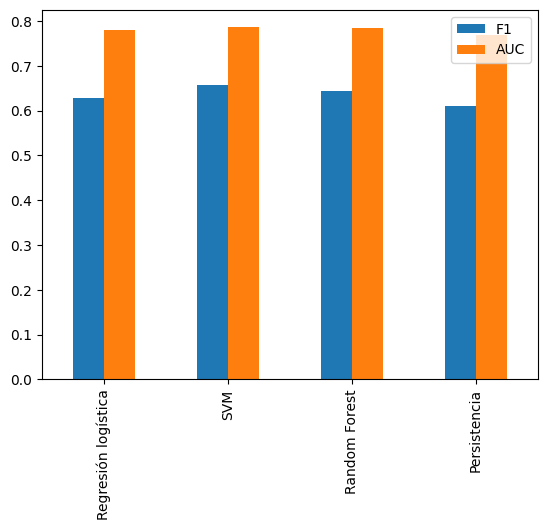

In [ ]:
tabla[["F1", "AUC"]].plot(kind="bar")

### Gráfico 11. Matriz de confusión de la SVM en porcentajes

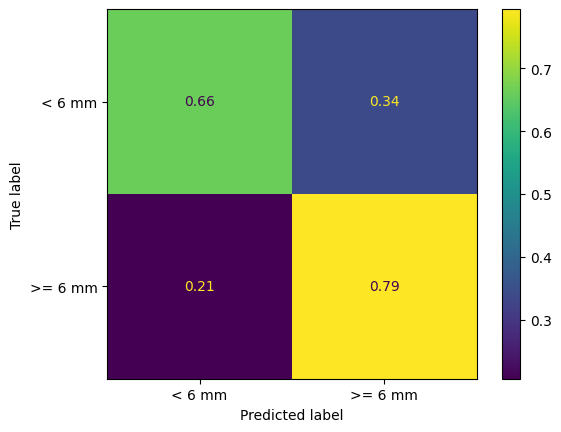

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_te, res_svm["pred"], normalize="true", display_labels=["< 6 mm", ">= 6 mm"])

### Gráfico 12. Matriz de confusión del Random Forest en porcentajes

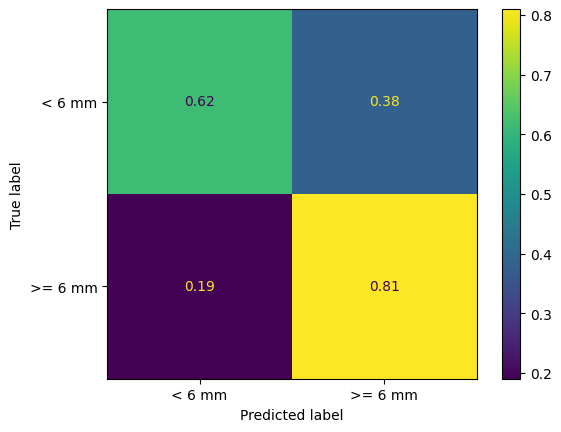

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_te, res_rf["pred"], normalize="true", display_labels=["< 6 mm", ">= 6 mm"])

### Gráfico 13. Matriz de confusión de la regresión logística en porcentajes

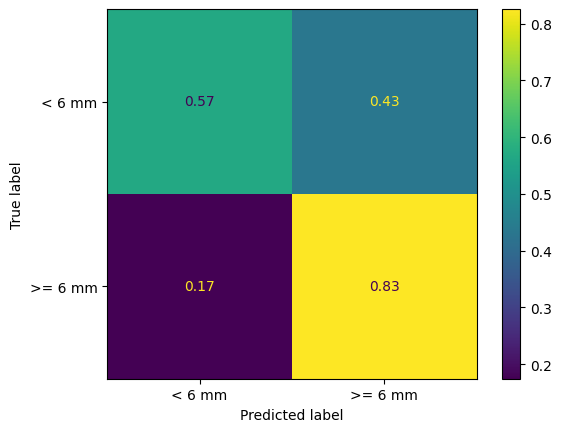

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_te, res_log["pred"], normalize="true", display_labels=["< 6 mm", ">= 6 mm"])

Las matrices muestran el porcentaje de aciertos por clase. La SVM detecta el 79 % de los días con lluvia importante y acierta el 66 % de los días sin ella. El Random Forest detecta un poco más, el 81 %, pero acierta menos días sin lluvia, el 62 %. La regresión logística detecta el 83 % de los días con lluvia, pero solo acierta el 57 % de los días sin lluvia, por eso da más falsas alarmas.

### Gráfico 14. Importancia de las variables en el Random Forest

<Axes: >

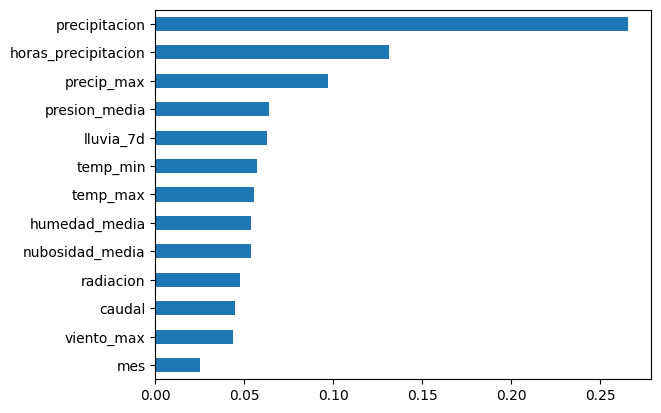

In [ ]:
pd.Series(res_rf["modelo"].feature_importances_, index=predictores).sort_values().plot(kind="barh")

La variable que más pesa en el Random Forest es la lluvia de hoy, seguida de las horas con lluvia y la lluvia máxima de un punto de la cuenca. Después vienen la presión y la lluvia de los últimos 7 días. El mes es la que menos aporta, porque su efecto ya está en las variables de lluvia y humedad.

### 7.5 Probabilidad baja, media o alta de lluvia importante
El Random Forest entrega una probabilidad para cada día. Se agrupa en tres niveles y se revisa qué porcentaje de días de prueba tuvo de verdad lluvia importante en cada nivel.

In [ ]:
# Probabilidad del Random Forest agrupada en tres niveles: baja, media y alta
nivel = pd.cut(res_rf["modelo"].predict_proba(cuenca.loc[prueba, predictores])[:, 1], [0, 0.4, 0.6, 1], labels=["baja", "media", "alta"], include_lowest=True)

In [ ]:
y_te.groupby(nivel, observed=True).agg(["mean", "count"])

,mean,count
baja,0.131078,473
media,0.391975,324
alta,0.652174,299


Cuando el Random Forest da probabilidad baja, solo el 13 % de esos días tuvo lluvia importante. Con probabilidad media fue el 39 % y con probabilidad alta el 65 %. Los niveles funcionan: a mayor nivel, mayor lluvia real. Así el resultado se puede comunicar como probabilidad baja, media o alta de que llegue agua a Mazar, como sugirió la profesora.

### 7.6 Modelo elegido

| Modelo | Papel en el proyecto |
|---|---|
| SVM con kernel RBF | **Modelo final.** Tiene el mejor F1 y el mejor AUC en prueba |
| Random Forest | Segundo modelo. Queda cerca de la SVM, entrega probabilidades para los niveles baja, media y alta, y muestra qué variables pesan más |
| Regresión logística | Modelo base. Es el más sencillo de explicar y sirve para comparar |

La diferencia entre la SVM y el Random Forest es pequeña, poco más de 0,01 de F1, así que los dos son buenas opciones. Se elige la SVM por tener el mejor resultado y se usa el Random Forest para explicar las variables y expresar el resultado en niveles de probabilidad.

## 8. Conclusión
- Los datos de la cuenca del Paute siguen completos: 4.011 días sin faltantes ni duplicados.
- Con un minidataset de 364 días de caudal real de CELEC se comprobó que la lluvia de Open-Meteo sí se refleja en el agua que llega a Mazar, con una correlación de 0,61 entre la lluvia de ayer y el caudal de hoy, y que el umbral de 6 mm está respaldado con datos reales.
- Se entrenaron y compararon tres modelos. La SVM es el modelo final, con F1 de 0,657 y AUC de 0,786, seguida de cerca por el Random Forest. Los tres superan a la persistencia.
- El Random Forest permite expresar el resultado como probabilidad baja, media o alta de lluvia importante, que es la forma en que se presentará la predicción para Mazar.